# Practical 2 — Data Construction and Data Transformation

**Lectures:** 3. Data Construction · 4. Data Transformation

"Garbage in, garbage out": a model can only be as good as its data. In this practical you will
take a messy real-world dataset — **California housing** (one row per census district, 1990) —
and turn it into a clean numerical feature matrix ready for learning. You will:

* check whether a **sample** is representative of the population (Kolmogorov–Smirnov and χ² tests);
* compare **random** and **stratified** train/validation/test **splitting**;
* look at **imbalanced** labels;
* implement **min–max normalisation** and **standardisation** yourself, plus binning and log scaling;
* **one-hot encode** a categorical feature;
* deal with **missing data**;
* package everything in a scikit-learn `Pipeline` / `ColumnTransformer` — without **data leakage**.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(0)

HOUSING_URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
housing = pd.read_csv(HOUSING_URL)
housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 1. Explore before you transform (≈15 min)
**TODO 1.1** Using `info()`, `describe()`, `value_counts()` and histograms (`housing.hist(bins=50, figsize=(12, 8))`), find:
* which column is categorical, and what its categories are;
* which column has missing values, and how many;
* two numerical features that are strongly **skewed**, and any features that look **capped**
  (a suspicious spike at the maximum value).

info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB
describe
          longitude      latitude  housing_median_age   total_rooms  \
count  20640.000000  20640.000000        20640.000000  20640.000000   
mean    -119.569704     35.631861           28.639486   2635.763081   
std        2.003532     

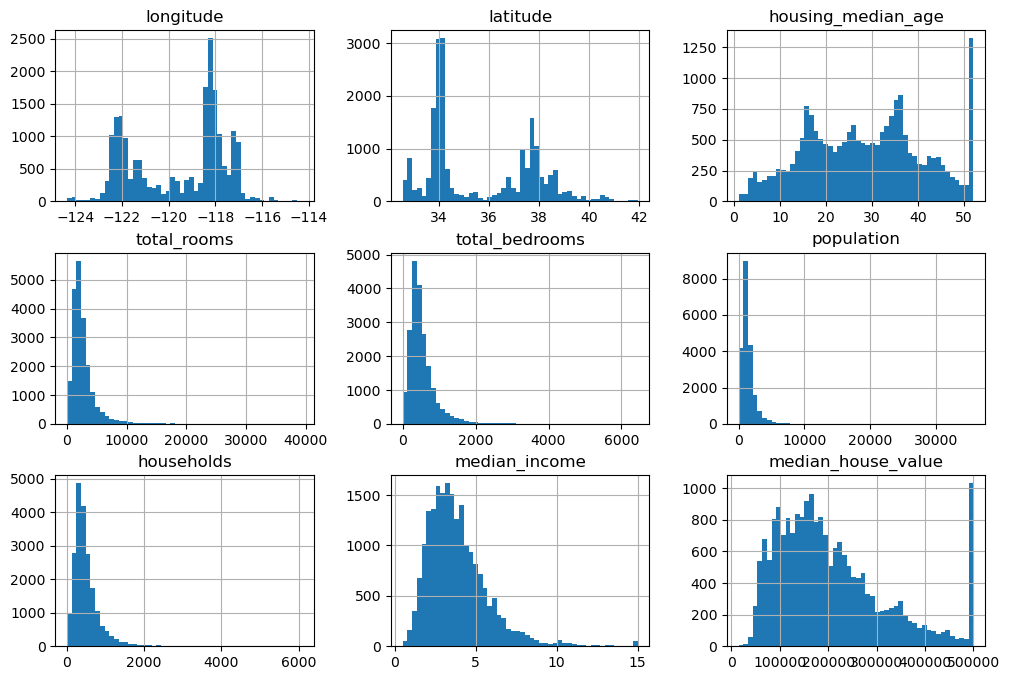

In [3]:
print("info")
housing.info()
print("describe")
print(housing.describe())
print("value counts")
print(housing["ocean_proximity"].value_counts())
print("histograms")
housing.hist(bins=50, figsize=(12,8))
print("missing value counts")
print(housing.isna().sum())

The ocean_proximity column is catagorical with catagories :
*<1H OCEAN     9136
*INLAND        6551
*NEAR OCEAN    2658
*NEAR BAY      2290
*ISLAND           5. 
The column with missing values is total_bedrooms with 207 missing values
The total rooms and total bedrooms look strongly skewed and the housing_median_age and median_house_value both have strong spikes that appear cut off.

## 2. Data sampling (≈15 min)
Suppose training on all 20 640 rows were too expensive and we only used a random 5 % sample.
Is the sample representative?

For each **numerical** column, use the two-sample Kolmogorov–Smirnov test
(`stats.ks_2samp(sample[col].dropna(), population[col].dropna())`); for the **categorical**
column use Pearson's χ² goodness-of-fit test comparing the sample's category counts with the
counts *expected* from the population proportions (`stats.chisquare(observed, expected)`).

**TODO 2.1** Write `check_sample(sample, population)` returning a DataFrame with one p-value per
column. Following the lecture, accept the sample only if **every** p-value is ≥ 0.05.

In [4]:
def check_sample(sample, population, cat_cols=("ocean_proximity",)):
    rows = []
    category = cat_cols[0]
    
    num_cols = population.columns.drop(category).tolist()
    for col in num_cols:
        res = stats.ks_2samp(sample[col].dropna(), population[col].dropna())
        rows.append([col, "Kolmogorov-Smirnov", res.pvalue])

    categories = population[category].value_counts().index

    observed = sample[category].value_counts().reindex(categories, fill_value=0)

    expected = population[category].value_counts().reindex(categories, fill_value=0)
    expected *= observed.sum() / expected.sum()

    stat, p = stats.chisquare(observed.dropna(), expected.dropna())
    rows.append([category, "Chi-Square", p])

    return pd.DataFrame(rows, columns=["column", "test", "p_value"])

sample = housing.sample(frac=0.05, random_state=1)
result1 = check_sample(sample, housing)
print(result1)
print("Accept sample?", bool((result1.p_value >= 0.05).all()))

               column                test   p_value
0           longitude  Kolmogorov-Smirnov  0.405462
1            latitude  Kolmogorov-Smirnov  0.132832
2  housing_median_age  Kolmogorov-Smirnov  0.625337
3         total_rooms  Kolmogorov-Smirnov  0.327333
4      total_bedrooms  Kolmogorov-Smirnov  0.328766
5          population  Kolmogorov-Smirnov  0.268092
6          households  Kolmogorov-Smirnov  0.133774
7       median_income  Kolmogorov-Smirnov  0.332960
8  median_house_value  Kolmogorov-Smirnov  0.515252
9     ocean_proximity          Chi-Square  0.354328
Accept sample? True


**TODO 2.2** Now draw a deliberately *biased* sample — e.g. only districts with
`median_income > 3` — and run the same check. Which columns fail?

In [5]:
biasSample = housing[housing["median_income"] > 3].sample(n=len(sample), random_state=1)
result2 = check_sample(biasSample, housing)
print(result2)
print("Accept sample?", bool((result2.p_value >= 0.05).all()))
# The total_rooms, median_income, median_house_value and ocean_proximity columns fail

               column                test        p_value
0           longitude  Kolmogorov-Smirnov   8.676974e-02
1            latitude  Kolmogorov-Smirnov   1.272931e-01
2  housing_median_age  Kolmogorov-Smirnov   7.977943e-01
3         total_rooms  Kolmogorov-Smirnov   2.257025e-06
4      total_bedrooms  Kolmogorov-Smirnov   9.276643e-01
5          population  Kolmogorov-Smirnov   8.229274e-01
6          households  Kolmogorov-Smirnov   7.372934e-01
7       median_income  Kolmogorov-Smirnov  1.003828e-113
8  median_house_value  Kolmogorov-Smirnov   2.177073e-40
9     ocean_proximity          Chi-Square   1.721201e-12
Accept sample? False


In [6]:
pd.merge(result1, result2, on=["column", "test"])

,column,test,p_value_x,p_value_y
0,longitude,Kolmogorov-Smirnov,0.405462,8.676974e-02
1,latitude,Kolmogorov-Smirnov,0.132832,1.272931e-01
2,housing_median_age,Kolmogorov-Smirnov,0.625337,7.977943e-01
3,total_rooms,Kolmogorov-Smirnov,0.327333,2.257025e-06
4,total_bedrooms,Kolmogorov-Smirnov,0.328766,9.276643e-01
5,population,Kolmogorov-Smirnov,0.268092,8.229274e-01
6,households,Kolmogorov-Smirnov,0.133774,7.372934e-01
7,median_income,Kolmogorov-Smirnov,0.332960,1.003828e-113
8,median_house_value,Kolmogorov-Smirnov,0.515252,2.177073e-40
9,ocean_proximity,Chi-Square,0.354328,1.721201e-12


## 3. Data splitting (≈20 min)
Median income is known to be the most important predictor of house value. If our test set
happened to contain unusually many high-income districts, our test error would be misleading.
**Stratified sampling** preserves the proportion of each *stratum* in every split.

**TODO 3.1** Create an `income_cat` column by binning `median_income` into the 5 bins
`[0, 1.5, 3, 4.5, 6, np.inf]` with `pd.cut`. Then produce a **60 / 20 / 20
train / validation / test** split twice — once purely at random, once stratified on
`income_cat` — using two calls to `train_test_split` with `random_state=42`.
Compare the `income_cat` proportions of each test set with the full dataset in a table.

In [7]:
from sklearn.model_selection import train_test_split

housing["income_cat"] = pd.cut(housing["median_income"], bins=[0, 1.5, 3, 4.5, 6, np.inf], labels=[1, 2, 3, 4, 5])

def three_way_split(df, stratify_col=None, seed=42):
    """Return train, val, test DataFrames in proportions 60/20/20."""
    strata = df[stratify_col] if stratify_col else None
    train, temp = train_test_split(df, test_size=0.4, random_state=seed, stratify=strata)

    temp_strata = temp[stratify_col] if stratify_col else None
    val, test = train_test_split(temp, test_size=0.5, random_state=seed, stratify=temp_strata)
    return train, val, test

train_r, val_r, test_r = three_way_split(housing)
train_s, val_s, test_s = three_way_split(housing, "income_cat")

compare = pd.DataFrame({
    "overall": housing.income_cat.value_counts(normalize=True),
    "random test": test_r.income_cat.value_counts(normalize=True),
    "stratified test": test_s.income_cat.value_counts(normalize=True),
}).sort_index()
compare["random error %"] = 100 * (compare["random test"] / compare["overall"] - 1)
compare["strat. error %"] = 100 * (compare["stratified test"] / compare["overall"] - 1)
print(len(train_s), len(val_s), len(test_s))
compare.round(4)

12384 4128 4128


,overall,random test,stratified test,random error %,strat. error %
income_cat,,,,,
1,0.0398,0.0380,0.0400,-4.5012,0.3650
2,0.3188,0.3166,0.3188,-0.6990,-0.0152
3,0.3506,0.3481,0.3505,-0.7048,-0.0138
4,0.1763,0.1751,0.1764,-0.6595,0.0275
5,0.1144,0.1221,0.1143,6.6892,-0.0847


**Imbalanced data.** Classification labels are often far from balanced. Look at the Titanic
dataset below: what fraction of passengers survived? If you built a classifier that always predicted
"did not survive", what accuracy would it get? *(Keep this "accuracy paradox" in mind for Practical 6.)*

In [8]:
titanic = pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv")
survivors = titanic["survived"].value_counts()
print(f"Num who died = {round(100*survivors[0]/survivors.sum(),2)}%, Num who survived = {round(100*survivors[1]/survivors.sum(),2)}%")
#Would give 61.6% accuracy to a did not survive prediction classifier

Num who died = 61.62%, Num who survived = 38.38%


From now on we work with the **stratified** split and drop `income_cat`. Our target `y` is
`median_house_value`.

In [9]:
for d in (train_s, val_s, test_s):
    d.drop(columns="income_cat", inplace=True)
X_train, y_train = train_s.drop(columns="median_house_value"), train_s["median_house_value"].to_numpy()
X_val, y_val = val_s.drop(columns="median_house_value"), val_s["median_house_value"].to_numpy()
X_test, y_test = test_s.drop(columns="median_house_value"), test_s["median_house_value"].to_numpy()
num_cols = X_train.columns.drop("ocean_proximity").tolist()

## 4. Transforming numerical data (≈25 min)
**TODO 4.1** Implement the two scalers below as classes with `fit` (learn statistics from
the data passed in) and `transform` (apply them). Formulas from the lecture:

* min–max: $x' = \dfrac{x - \min(x)}{\max(x) - \min(x)}$
* standardisation (z-score): $x' = \dfrac{x - \mu}{\sigma}$

Check your results against `MinMaxScaler` and `StandardScaler` using `np.allclose`.

In [10]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

class MyMinMaxScaler:
    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.min = X.min(axis=0)
        self.max = X.max(axis=0)
        return self
    def transform(self, X):
        X = np.asarray(X, dtype=float)
        return (X - self.min)/(self.max - self.min)

class MyStandardScaler:
    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.mean = X.mean(axis=0)
        self.sd = X.std(axis=0)
        return self
    def transform(self, X):
        X = np.asarray(X, dtype=float)
        return (X - self.mean)/self.sd

Xn = X_train[num_cols].dropna().to_numpy()
print(np.allclose(MyMinMaxScaler().fit(Xn).transform(Xn), MinMaxScaler().fit_transform(Xn)))
print(np.allclose(MyStandardScaler().fit(Xn).transform(Xn), StandardScaler().fit_transform(Xn)))

True
True


**TODO 4.2 — Data leakage.** Why must we call `fit` on the **training** set only and then
`transform` the validation and test sets with the training statistics? Fit a
`MyMinMaxScaler` on the training data, transform the test data, and print the min and max of
the transformed test columns. Are they exactly 0 and 1? Why is that fine?

In [11]:
Xtrain = X_train[num_cols].dropna().to_numpy()
Xtrans = X_test[num_cols].dropna().to_numpy()
myScalar = MyMinMaxScaler().fit(Xtrain)
transformedData = myScalar.transform(Xtrans)
print(transformedData.min(axis=0))
print(transformedData.max(axis=0))

[5.00500501e-03 1.06723586e-03 0.00000000e+00 2.37272943e-04
 1.82848784e-04 5.60553827e-05 1.92789666e-04 0.00000000e+00]
[0.97597598 1.00320171 1.         1.03646094 1.17809472 0.80055495
 1.17216117 1.        ]


They are not all exactly 0 for all the mins nor exactly 1 for all the maxes, however they are close enough which is fine since they will only be exact if the min/max on the testing data is the same as that on the training data which is not expected to be true

**TODO 4.3 — Log scaling and binning.** `population` is heavily right-skewed.
(a) Plot histograms of `population` and `np.log1p(population)` side by side.
(b) Bin `median_income` into 5 bins with **equal-width** binning (`pd.cut`) and with
**quantile** binning (`pd.qcut`), and print the number of districts in each bin. Which is more
suitable for a skewed feature, and why?

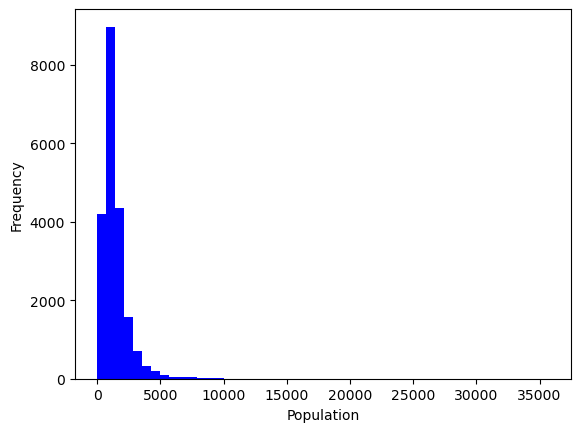

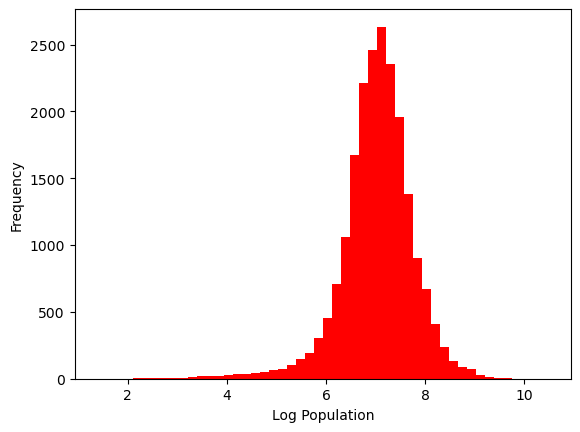

median_income
(0.485, 3.4]    9683
(3.4, 6.3]      9088
(6.3, 9.2]      1488
(9.2, 12.1]      271
(12.1, 15.0]     110
Name: count, dtype: int64
median_income
(2.352, 3.141]    4131
(0.499, 2.352]    4130
(3.967, 5.11]     4128
(5.11, 15.0]      4128
(3.141, 3.967]    4123
Name: count, dtype: int64


In [12]:
plt.hist(housing["population"], bins=50, color="blue")
plt.xlabel("Population")
plt.ylabel("Frequency")
plt.show()
plt.hist(np.log1p(housing["population"]), bins=50, color="red")
plt.xlabel("Log Population")
plt.ylabel("Frequency")
plt.show()

eqBinnedMedInc = pd.cut(housing["median_income"], bins=5)
quBinnedMedInc = pd.qcut(housing["median_income"], q=5)
print(eqBinnedMedInc.value_counts())
print(quBinnedMedInc.value_counts())

The quantile binning is more suitable for a skewed feature as if you bin a skewed feature using equal size bins you end up with the majority of values existing in a small fraction of the bins while the rest of the bins have far fewer values assigned (as shown above). In quantile binning all bins recieve the same amount of values so they are seperated into equal size groups which is more useful in calculations etc.

## 5. Categorical data and missing data (≈15 min)
**TODO 5.1** One-hot encode `ocean_proximity` twice: with `pd.get_dummies` and with
`OneHotEncoder(handle_unknown="ignore")`. Why should we *not* simply map the categories to the
integers 0–4 (ordinal encoding) for this feature?

**TODO 5.2** `total_bedrooms` is missing for about 1 % of districts. Compare three strategies:
(i) drop those rows, (ii) fill with the **mean**, (iii) fill with the **median** (use
`SimpleImputer`). Which statistic is the better choice for a skewed feature?

In [13]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

oProx = housing[["ocean_proximity"]]
pdEncodedHousing = pd.get_dummies(oProx)
encoder = OneHotEncoder(handle_unknown="ignore")
skEncodedHousing = encoder.fit_transform(oProx)
# We shouldnt simply map the catagories to integers since integers 0-4 have a given order and value 
# that isnt relevant here but could be confused and used as if they hold a meaningful numerical value

In [14]:
# strategy 1
totalBedrooms = housing[["total_bedrooms"]]
total_bedrooms1 = totalBedrooms.dropna().to_numpy()
print(total_bedrooms1.shape)
# strategy 2
total_bedrooms2 = SimpleImputer(strategy="mean").fit(totalBedrooms).transform(totalBedrooms)
print(total_bedrooms2.shape)
# strategy 3
total_bedrooms3 = SimpleImputer(strategy="median").fit(totalBedrooms).transform(totalBedrooms)
print(total_bedrooms3.shape)

(20433, 1)
(20640, 1)
(20640, 1)


Strategy 1 misses out on observations and can change the data distribution but is simple. 
Strategy 2 and 3 preserve the row count, with strategy 2 using the mean which is more sutiable for non-skewed features as it best summarises the data but in a skewed feature the mean wont be representative of most of the data which falls into a specific maximum value so here we would chose strategy 3 which chooses the value that most of the data falls into which will move towards the skew.

## 6. Putting it together: a preprocessing pipeline (≈10 min)
In practice we chain all these steps so they are fitted on the training data *once* and
applied identically everywhere else.

**TODO 6.1** Build a `ColumnTransformer` that
* for the numerical columns: imputes with the median, then standardises;
* for `ocean_proximity`: one-hot encodes.

Fit it on `X_train`, transform all three sets and print the shapes. Then fit a
`LinearRegression` on the processed training data and report the validation RMSE — a first taste of Practical 3!

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

num_pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())

preprocess = ColumnTransformer([("numerical", num_pipe, num_cols), 
                                ("catagorical", OneHotEncoder(handle_unknown="ignore"), ["ocean_proximity"])])

X_train_proc = preprocess.fit_transform(X_train)
X_val_proc = preprocess.transform(X_val)
X_test_proc = preprocess.transform(X_test)

print(f"After transforming, the shape of the training data is {X_train_proc.shape},\n the shape of the validation data is {X_val_proc.shape},\n and the shape of the testing data is {X_test_proc.shape}.")

model = LinearRegression().fit(X_train_proc, y_train)
val_pred = model.predict(X_val_proc)
val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))
print(f"The validation RMSE is {round(val_rmse,2)}")

After transforming, the shape of the training data is (12384, 13),
 the shape of the validation data is (4128, 13),
 and the shape of the testing data is (4128, 13).
The validation RMSE is 69711.17


## 7. Extension
* Engineer new features: `rooms_per_household`, `bedrooms_per_room`, `population_per_household`.
  Add them to the pipeline (a `FunctionTransformer` helps). Does the validation RMSE improve?
* Apply a log transform to the skewed count features inside the pipeline. Any better?

In [16]:
# YOUR CODE HERE

## Lab report checklist (Practical 2)
1. A table of p-values from your representative-sample check, for a random sample and a biased sample, and what you conclude.
2. The random-versus-stratified comparison table, with one or two sentences on why stratification matters.
3. A figure showing the effect of a transformation (e.g. log scaling or binning) on a skewed feature.
4. A description of your final preprocessing pipeline (which transformation for which column, and why), the resulting feature-matrix shape, and your validation RMSE.
5. A short explanation of data leakage and how your pipeline avoids it.